# A predictor trained on the chosen encoder layer (plan item 8)

Notebooks 09 and 10 showed that the encoder's layer 32 holds more nearest-neighbour signal than the final layer (chosen on synthetic validation data, confirmed once on test). A nearest-neighbour score needs a memory bank of every nominal training token. The question here is whether a **memory-free** predictor, trained on layer-32 tokens with **exactly the baseline recipe**, can use that signal.

**What differs from the baseline, and what does not**

| | Baseline | This notebook |
| --- | --- | --- |
| Tokens the predictor reads and predicts | final-layer latents | layer-32 latents (token layer norm), `data/cache/latents_layer32*` |
| Predictor architecture, optimiser, masks, epochs, seed | `configs/predictor/base.yaml`, inference-aligned 4x4 blocks, seed 0 | identical (CLI defaults), checkpoints in `checkpoints/predictors_layer32/` |
| Scoring | `1 - cos`, adaptive, default tau | the same, plus the notebook 06 settings (per-position z-score, `k = 3`) **carried over unchanged** |

The cache identity of the layer-32 latents is a derived hash (checkpoint hash + layer + normalisation), so a layer-32 predictor cannot be loaded against final-layer latents or the other way round: `load_predictor_checkpoint` raises.

**Settings are not re-selected.** The notebook 06 settings were chosen for the final-layer predictor on the synthetic set. They are reused here as declared, for both predictors, so the headline comparison (layer 32 versus final layer under the *same* scoring) is clean. The test split is scored once per row.

**Rows** (all coarse + adaptive at the default `tau`, so 16 to 16.2 masks per image):

1. `final / baseline score`: baseline predictors, max score (the baseline of notebooks 04 to 07).
2. `final / selected`: baseline predictors with the notebook 06 settings (notebook 07's result).
3. `layer 32 / baseline score`: layer-32 predictors, `1 - cos`, max score.
4. `layer 32 / selected`: layer-32 predictors with the notebook 06 settings.
5. context only: the layer-32 nearest-neighbour reference of notebook 10 (it needs a memory bank).

## 1. Configuration and data

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import yaml
from PIL import Image

try:
    display
except NameError:
    display = print

candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next((p for p in candidates if (p / 'configs').is_dir() and (p / 'src').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from the repository or its notebooks directory.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

CATEGORIES = ('bottle', 'capsule', 'hazelnut')
LAYER = 32
ENCODER_CHECKPOINT = PROJECT_ROOT / 'checkpoints' / 'IN22K-vit.g.16-600e.pth.tar'
SETS = {
    'final': {'predictors': PROJECT_ROOT / 'checkpoints' / 'predictors', 'train_root': PROJECT_ROOT / 'data' / 'cache' / 'latents',
              'test_root': PROJECT_ROOT / 'data' / 'cache' / 'latents_test', 'encoder_name': 'ijepa_vit_g16_in22k_ep44'},
    'layer 32': {'predictors': PROJECT_ROOT / 'checkpoints' / 'predictors_layer32', 'train_root': PROJECT_ROOT / 'data' / 'cache' / f'latents_layer{LAYER}',
                 'test_root': PROJECT_ROOT / 'data' / 'cache' / f'latents_layer{LAYER}_test', 'encoder_name': f'ijepa_vit_g16_in22k_ep44_layer{LAYER}'},
}
SELECTION06 = PROJECT_ROOT / 'results' / 'improvements' / 'synthetic_val' / 'selected_settings.json'
OUTPUT_ROOT = Path(os.environ.get('LAYER_PREDICTOR_OUTPUT', PROJECT_ROOT / 'results' / 'improvements' / 'layer_predictor'))
OVERWRITE = False
OUTPUT_FILES = ('layer_predictor_metrics.csv', 'bootstrap_deltas.csv', 'layer_predictor_summary.json')
MASKING_CONFIG_PATH = PROJECT_ROOT / 'configs' / 'masking' / 'coarse_to_fine.yaml'
DATA_CONFIG = yaml.safe_load((PROJECT_ROOT / 'configs' / 'data' / 'mvtec.yaml').read_text(encoding='utf-8'))
VAL_FRACTION, SPLIT_SEED = float(DATA_CONFIG['nominal_split']['val_fraction']), int(DATA_CONFIG['nominal_split']['seed'])
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
N_BOOTSTRAP, BOOTSTRAP_SEED, POSITION_STD_FLOOR_FRACTION = 1000, 0, 0.5

if not OVERWRITE:
    existing = [OUTPUT_ROOT / n for n in OUTPUT_FILES if (OUTPUT_ROOT / n).exists()]
    if existing:
        raise FileExistsError('Refusing to overwrite: ' + ', '.join(map(str, existing)) + ' (set OVERWRITE = True)')
selection = json.loads(SELECTION06.read_text(encoding='utf-8'))
if selection['test_used_for_selection'] is not False:
    raise ValueError('The selection file says the test split influenced the choice.')
SELECTED = selection['selected_settings']
if SELECTED['family'] != 'pos_zscore' or SELECTED['sigma'] != 0.0 or SELECTED['tau'] != 'default':
    raise ValueError('This notebook applies the notebook 06 selection (pos_zscore, sigma 0, default tau); the selection changed.')
K, LAM_SEL = int(SELECTED['k']), float(SELECTED['lam'])
print('settings carried over from notebook 06:', SELECTED)

settings carried over from notebook 06: {'family': 'pos_zscore', 'k': 3, 'lam': 1.0, 'sigma': 0.0, 'tau': 'default'}


In [2]:
from ijepa_ad.caching.cache_schema import CacheExpectations, PreprocessingSpec
from ijepa_ad.caching.latent_cache import compute_file_sha256
from ijepa_ad.data.mvtec_dataset import validate_category_splits
from ijepa_ad.data.splits import split_nominal_train_val
from ijepa_ad.data.transforms import PreprocessConfig
from ijepa_ad.evaluation.metrics import aupro, image_auroc, pixel_auroc
from ijepa_ad.evaluation.runner import EMBEDDING_DIM, NUM_TOKENS, PATCH_SIZE
from ijepa_ad.inference import MaskedLatentScorer, load_masking_settings, load_predictor_checkpoint_with_provenance
from ijepa_ad.masking.score_maps import upsample_patch_scores
from ijepa_ad.predictor.cache_dataset import load_cached_latent_dataset
from ijepa_ad.scoring import PositionNormaliser

import hashlib

REAL_SHA = compute_file_sha256(ENCODER_CHECKPOINT)
IDENTITY = {'final': REAL_SHA, 'layer 32': hashlib.sha256(f'{REAL_SHA}|layer={LAYER}|token_layer_norm|v1'.encode()).hexdigest()}
MASKING_SETTINGS = load_masking_settings(MASKING_CONFIG_PATH)
DEFAULT_TAU, LAM_DEFAULT = MASKING_SETTINGS['threshold'], MASKING_SETTINGS['lam']
SPEC = PreprocessingSpec.from_config(PreprocessConfig(image_size=int(DATA_CONFIG['preprocessing']['image_size'])))


def expectations(set_name, category, split, samples):
    return CacheExpectations(category=category, split=split, encoder_name=SETS[set_name]['encoder_name'], checkpoint_sha256=IDENTITY[set_name],
                             patch_size=PATCH_SIZE, embedding_dim=EMBEDDING_DIM, preprocessing=SPEC,
                             sample_ids=tuple(s.image_id for s in samples), num_tokens=NUM_TOKENS)


def load_ground_truth(annotation):
    if annotation.mask_path is None:
        with Image.open(annotation.image_path) as image:
            width, height = image.size
        return np.zeros((height, width), dtype=bool)
    with Image.open(annotation.mask_path) as mask_image:
        return np.asarray(mask_image.convert('L')) > 0


PREDICTORS, VAL, TESTSET, TEST = {}, {}, {}, {}
for category in CATEGORIES:
    root = next(r for r in (PROJECT_ROOT / DATA_CONFIG['root'], PROJECT_ROOT / 'dataset', PROJECT_ROOT / 'dataset' / category) if (r / category / 'train').is_dir())
    train_ds, test_ds = validate_category_splits(root, category)
    nominal = split_nominal_train_val(train_ds.samples, val_fraction=VAL_FRACTION, seed=SPLIT_SEED,
                                      min_train=int(DATA_CONFIG['nominal_split']['min_train']), min_val=int(DATA_CONFIG['nominal_split']['min_val']))
    for name, cfg in SETS.items():
        VAL[(name, category)] = load_cached_latent_dataset(cfg['train_root'], expectations(name, category, 'val', nominal.val), samples=train_ds.samples)
        TESTSET[(name, category)] = load_cached_latent_dataset(cfg['test_root'], expectations(name, category, 'test', test_ds.samples), samples=test_ds.samples)
        PREDICTORS[(name, category)], prov = load_predictor_checkpoint_with_provenance(
            cfg['predictors'] / f'{category}_cosine.pt', category=category, encoder_sha256=IDENTITY[name], device=DEVICE)
        print(f'{name:>9} / {category}: val={len(VAL[(name, category)])}, test={len(TESTSET[(name, category)])}, predictor status={prov["status"]}, mask_strategy={prov["mask_strategy"]}')
    ref = TESTSET[('final', category)]
    TEST[category] = {'labels': np.asarray([int(s.annotation.label != 'good') for s in ref]), 'masks': [load_ground_truth(s.annotation) for s in ref]}
    if list(TESTSET[('layer 32', category)].sample_ids) != list(ref.sample_ids):
        raise ValueError('test image order differs between the two caches')

# cross-use must be rejected (the derived identity at work)
try:
    load_predictor_checkpoint_with_provenance(SETS['layer 32']['predictors'] / 'bottle_cosine.pt', category='bottle', encoder_sha256=REAL_SHA, device=DEVICE)
    raise AssertionError('a layer-32 predictor was accepted for the final-layer encoder identity')
except ValueError as error:
    print('layer-32 predictor with the final-layer identity is rejected:', error)

    final / bottle: val=21, test=83, predictor status=complete, mask_strategy=inference_aligned
 layer 32 / bottle: val=21, test=83, predictor status=complete, mask_strategy=inference_aligned
    final / capsule: val=22, test=132, predictor status=complete, mask_strategy=inference_aligned
 layer 32 / capsule: val=22, test=132, predictor status=complete, mask_strategy=inference_aligned
    final / hazelnut: val=39, test=110, predictor status=complete, mask_strategy=inference_aligned
 layer 32 / hazelnut: val=39, test=110, predictor status=complete, mask_strategy=inference_aligned
layer-32 predictor with the final-layer identity is rejected: predictor checkpoint was trained with a different encoder


## 2. Training summary (validation only)

Read back from the saved checkpoints: epochs, best validation loss and the recipe fields. The validation loss is the cosine loss on masked validation tokens; it is not comparable between feature sets (different latents), only between epochs of one run.

In [3]:
rows = []
for name in SETS:
    for category in CATEGORIES:
        payload = torch.load(SETS[name]['predictors'] / f'{category}_cosine.pt', map_location='cpu', weights_only=True)
        cfg = payload['training_config']
        rows.append({'features': name, 'category': category, 'epochs_run': len(payload['history']), 'best_epoch': payload['best_epoch'],
                     'best_val_loss': payload['best_val_loss'], 'train_images': len(payload['cache_provenance']['train']['sample_ids']),
                     'mask_strategy': cfg['mask_strategy'], 'block_size': cfg['block_size'], 'lr': cfg['learning_rate'], 'seed': cfg['seed']})
train_df = pd.DataFrame(rows)
display(train_df.round(4))
recipe_keys = ['mask_strategy', 'block_size', 'lr', 'seed']
assert all(train_df.groupby('category')[k].nunique().max() == 1 for k in recipe_keys), 'training recipes differ between the two feature sets'
print('recipe identical across feature sets')

recipe identical across feature sets


,features,category,epochs_run,best_epoch,best_val_loss,train_images,mask_strategy,block_size,lr,seed
0,final,bottle,94,84,0.0647,188,inference_aligned,4,0.0001,0
1,final,capsule,83,73,0.1302,197,inference_aligned,4,0.0001,0
2,final,hazelnut,100,97,0.1976,352,inference_aligned,4,0.0001,0
3,layer 32,bottle,100,99,0.0577,188,inference_aligned,4,0.0001,0
4,layer 32,capsule,83,73,0.1200,197,inference_aligned,4,0.0001,0
5,layer 32,hazelnut,100,100,0.1608,352,inference_aligned,4,0.0001,0


## 3. Score the test split

`run_scorer` is the loop of notebooks 04 to 07. For `selected` the per-position z-score is fitted on the nominal **validation** images of the same feature set (coarse windows in `fixed` mode, fine windows in `dense` mode) and applied to the adaptive pass's coarse and fine scores; the fine score only counts where the gate fired.

In [4]:
def run_scorer(predictor, dataset, mode, timed=False):
    scorer = MaskedLatentScorer(predictor, **MASKING_SETTINGS)
    if timed:
        scorer.score(dataset[0].latent.unsqueeze(0).to(DEVICE), mode=mode)
    coarse, fine, work, seconds = [], [], [], 0.0
    for sample in dataset:
        latent = sample.latent.unsqueeze(0).to(DEVICE)
        if timed and DEVICE == 'cuda':
            torch.cuda.synchronize()
        tick = time.perf_counter()
        result = scorer.score(latent, mode=mode)
        if timed and DEVICE == 'cuda':
            torch.cuda.synchronize()
        seconds += time.perf_counter() - tick
        coarse.append(result.coarse_scores.detach().cpu()); fine.append(result.fine_scores.detach().cpu()); work.append(result.evaluated_regions)
    return {'coarse': torch.stack(coarse), 'fine': torch.stack(fine), 'work': np.asarray(work), 'ms': 1000 * seconds / len(dataset), 'scorer': scorer}


def region_scores(scorer, coarse):
    out = torch.zeros_like(coarse)
    for window in scorer.coarse.windows():
        idx = list(window.token_indices)
        out[:, idx] = coarse[:, idx].mean(dim=1, keepdim=True)
    return out


PATCH, WORK, MS = {}, {}, {}
for name in SETS:
    for category in CATEGORIES:
        started = time.perf_counter()
        predictor, test = PREDICTORS[(name, category)], TESTSET[(name, category)]
        base = run_scorer(predictor, test, 'adaptive', timed=True)
        fired = region_scores(base['scorer'], base['coarse']) >= DEFAULT_TAU
        val_c = run_scorer(predictor, VAL[(name, category)], 'fixed')['coarse']
        val_f = run_scorer(predictor, VAL[(name, category)], 'dense')['fine']
        norm_c = PositionNormaliser.fit(val_c, divide=True, std_floor_fraction=POSITION_STD_FLOOR_FRACTION)
        norm_f = PositionNormaliser.fit(val_f, divide=True, std_floor_fraction=POSITION_STD_FLOOR_FRACTION)
        PATCH[(name, category, 'baseline score')] = base['coarse'] + LAM_DEFAULT * base['fine']
        PATCH[(name, category, 'selected')] = norm_c.apply(base['coarse']) + LAM_SEL * fired.float() * norm_f.apply(base['fine'])
        WORK[(name, category)], MS[(name, category)] = base['work'], base['ms']
        print(f'{name:>9} / {category}: {time.perf_counter() - started:.0f}s, masks/image {base["work"].mean():.2f}, {base["ms"]:.0f} ms/image')

C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\.venv\Lib\site-packages\torch\nn\modules\transformer.py:685: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:263.)
  return torch._transformer_encoder_layer_fwd(
    final / bottle: 8s, masks/image 16.19, 24 ms/image
    final / capsule: 9s, masks/image 16.00, 25 ms/image
    final / hazelnut: 13s, masks/image 16.15, 25 ms/image
 layer 32 / bottle: 7s, masks/image 16.19, 22 ms/image
 layer 32 / capsule: 8s, masks/image 16.00, 22 ms/image
 layer 32 / hazelnut: 12s, masks/image 16.58, 22 ms/image


## 4. Metrics and paired bootstrap

Same definitions as notebooks 05 and 07: image AUROC with the max and the top-`k` score, pixel AUROC and AUPRO against the full-resolution ground truth (200 thresholds), paired bootstrap on image AUROC (1,000 resamples, seed 0, the same resample for every comparison).

In [5]:
ROWS = [('final', 'baseline score'), ('final', 'selected'), ('layer 32', 'baseline score'), ('layer 32', 'selected')]
LABEL = {r: f'{r[0]} / {r[1]}' for r in ROWS}
RESULTS = {}
for category in CATEGORIES:
    labels, masks = TEST[category]['labels'], TEST[category]['masks']
    started = time.perf_counter()
    for name, scoring in ROWS:
        patch = PATCH[(name, category, scoring)]
        maps = [upsample_patch_scores(p, output_size=m.shape)[0, 0].numpy().astype(np.float32) for p, m in zip(patch, masks)]
        RESULTS[(category, name, scoring)] = {
            'scores': {'max': patch.max(dim=1).values.numpy(), f'top{K}': patch.topk(K, dim=1).values.mean(dim=1).numpy()},
            'pixel_auroc': pixel_auroc(maps, masks), 'aupro': aupro(maps, masks, num_thresholds=200)}
    print(f'{category}: evaluated in {time.perf_counter() - started:.0f}s')

metric_rows = []
for category in CATEGORIES:
    labels = TEST[category]['labels']
    for name, scoring in ROWS:
        r = RESULTS[(category, name, scoring)]
        metric_rows.append({'category': category, 'row': LABEL[(name, scoring)], 'image_auroc_max': image_auroc(labels, r['scores']['max']),
                            f'image_auroc_top{K}': image_auroc(labels, r['scores'][f'top{K}']), 'pixel_auroc': r['pixel_auroc'], 'aupro': r['aupro'],
                            'masks_per_image': float(WORK[(name, category)].mean()), 'scorer_ms_per_image': MS[(name, category)]})
metrics_df = pd.DataFrame(metric_rows)
for category in CATEGORIES:
    print(category)
    display(metrics_df[metrics_df.category == category].drop(columns='category').round(4).reset_index(drop=True))

# consistency with notebooks 05/07: the final-layer rows must be the same numbers
saved07 = pd.read_csv(PROJECT_ROOT / 'results' / 'improvements' / 'confirmation' / 'selected_vs_baseline.csv')
consistent = True
for category in CATEGORIES:
    for scoring, saved_name in (('baseline score', 'baseline'), ('selected', 'selected')):
        mine = metrics_df[(metrics_df.category == category) & (metrics_df.row == f'final / {scoring}')].iloc[0]
        row = saved07[(saved07.category == category) & (saved07.config == saved_name)].iloc[0]
        consistent &= abs(mine.pixel_auroc - row.pixel_auroc) < 1e-4 and abs(mine.aupro - row.aupro) < 1e-4 and abs(mine[f'image_auroc_top{K}'] - row[f'image_auroc_top{K}']) < 1e-4
print('final-layer rows reproduce notebook 07:', consistent)
if not consistent:
    raise AssertionError('The final-layer rows do not reproduce notebook 07.')

bottle: evaluated in 48s
capsule: evaluated in 80s
hazelnut: evaluated in 79s
bottle
capsule
hazelnut
final-layer rows reproduce notebook 07: True


,row,image_auroc_max,image_auroc_top3,pixel_auroc,aupro,masks_per_image,scorer_ms_per_image
0,final / baseline score,0.9246,0.9516,0.9295,0.7657,16.1928,24.2467
1,final / selected,0.9929,0.9976,0.9524,0.8309,16.1928,24.2467
2,layer 32 / baseline score,0.9587,0.9754,0.9791,0.9043,16.1928,21.9923
3,layer 32 / selected,0.9937,0.9992,0.9660,0.8714,16.1928,21.9923


,row,image_auroc_max,image_auroc_top3,pixel_auroc,aupro,masks_per_image,scorer_ms_per_image
0,final / baseline score,0.5217,0.5122,0.6845,0.0981,16.0,24.9789
1,final / selected,0.6223,0.6721,0.9011,0.5080,16.0,24.9789
2,layer 32 / baseline score,0.5429,0.6598,0.8357,0.3090,16.0,21.9813
3,layer 32 / selected,0.7208,0.7675,0.9307,0.6663,16.0,21.9813


,row,image_auroc_max,image_auroc_top3,pixel_auroc,aupro,masks_per_image,scorer_ms_per_image
0,final / baseline score,0.8021,0.8975,0.9067,0.5774,16.1455,25.0370
1,final / selected,0.8643,0.9393,0.9692,0.8118,16.1455,25.0370
2,layer 32 / baseline score,0.9464,0.9893,0.9861,0.8768,16.5818,22.4713
3,layer 32 / selected,0.9814,0.9932,0.9888,0.9013,16.5818,22.4713


In [6]:
def bootstrap_indices(labels):
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    pos, neg = np.flatnonzero(labels == 1), np.flatnonzero(labels == 0)
    return [np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(N_BOOTSTRAP)]


def verdict(low, high):
    return 'improves' if low > 0 else 'worsens' if high < 0 else 'inconclusive (CI contains 0)'


COMPARISONS = (
    ('HEADLINE: layer 32 / selected vs final / selected (top-k)', ('layer 32', 'selected', f'top{K}'), ('final', 'selected', f'top{K}')),
    ('layer 32 vs final, baseline score, max', ('layer 32', 'baseline score', 'max'), ('final', 'baseline score', 'max')),
    (f'layer 32 vs final, baseline score, top-{K}', ('layer 32', 'baseline score', f'top{K}'), ('final', 'baseline score', f'top{K}')),
    ('overall: layer 32 / selected (top-k) vs original baseline (final, max)', ('layer 32', 'selected', f'top{K}'), ('final', 'baseline score', 'max')),
)
boot_rows = []
for category in CATEGORIES:
    labels = TEST[category]['labels']
    indices = bootstrap_indices(labels)
    for label, (n1, s1, k1), (n2, s2, k2) in COMPARISONS:
        new, ref = RESULTS[(category, n1, s1)]['scores'][k1], RESULTS[(category, n2, s2)]['scores'][k2]
        deltas = np.asarray([image_auroc(labels[i], new[i]) - image_auroc(labels[i], ref[i]) for i in indices])
        low, high = np.percentile(deltas, [2.5, 97.5])
        boot_rows.append({'category': category, 'comparison': label, 'image_auroc': image_auroc(labels, new), 'reference_auroc': image_auroc(labels, ref),
                          'delta_image_auroc': image_auroc(labels, new) - image_auroc(labels, ref), 'ci95_low': low, 'ci95_high': high, 'verdict': verdict(low, high)})
boot_df = pd.DataFrame(boot_rows)
shown = boot_df.copy()
shown['CI95'] = shown.apply(lambda r: f'[{r.ci95_low:+.3f}, {r.ci95_high:+.3f}]', axis=1)
display(shown[['category', 'comparison', 'image_auroc', 'reference_auroc', 'delta_image_auroc', 'CI95', 'verdict']].round(4))

knn = PROJECT_ROOT / 'results' / 'improvements' / 'layer_confirmation' / 'layer_vs_final.csv'
if knn.exists():
    print('\ncontext only, notebook 10 (nearest-neighbour reference with a memory bank of all nominal training tokens):')
    display(pd.read_csv(knn).round(4))


context only, notebook 10 (nearest-neighbour reference with a memory bank of all nominal training tokens):


,category,comparison,image_auroc,reference_auroc,delta_image_auroc,CI95,verdict
0,bottle,HEADLINE: layer 32 / selected vs final / selec...,0.9992,0.9976,0.0016,"[+0.000, +0.007]",inconclusive (CI contains 0)
1,bottle,"layer 32 vs final, baseline score, max",0.9587,0.9246,0.0341,"[-0.024, +0.110]",inconclusive (CI contains 0)
2,bottle,"layer 32 vs final, baseline score, top-3",0.9754,0.9516,0.0238,"[-0.008, +0.063]",inconclusive (CI contains 0)
3,bottle,overall: layer 32 / selected (top-k) vs origin...,0.9992,0.9246,0.0746,"[+0.021, +0.153]",improves
4,capsule,HEADLINE: layer 32 / selected vs final / selec...,0.7675,0.6721,0.0953,"[+0.038, +0.150]",improves
5,capsule,"layer 32 vs final, baseline score, max",0.5429,0.5217,0.0211,"[-0.075, +0.114]",inconclusive (CI contains 0)
6,capsule,"layer 32 vs final, baseline score, top-3",0.6598,0.5122,0.1476,"[+0.039, +0.266]",improves
7,capsule,overall: layer 32 / selected (top-k) vs origin...,0.7675,0.5217,0.2457,"[+0.049, +0.457]",improves
8,hazelnut,HEADLINE: layer 32 / selected vs final / selec...,0.9932,0.9393,0.0539,"[+0.017, +0.101]",improves
9,hazelnut,"layer 32 vs final, baseline score, max",0.9464,0.8021,0.1443,"[+0.061, +0.239]",improves


,category,features,image_auroc_max,image_auroc_top3,pixel_auroc,aupro
0,bottle,final (cached),0.9992,1.0000,0.9727,0.8588
1,bottle,layer 32 (layer norm),1.0000,1.0000,0.9872,0.9371
2,capsule,final (cached),0.8045,0.8357,0.9155,0.5128
3,capsule,layer 32 (layer norm),0.9095,0.9095,0.9619,0.7705
4,hazelnut,final (cached),0.9875,0.9879,0.9791,0.8680
5,hazelnut,layer 32 (layer norm),0.9989,1.0000,0.9946,0.9408


saved to C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\results\improvements\layer_predictor


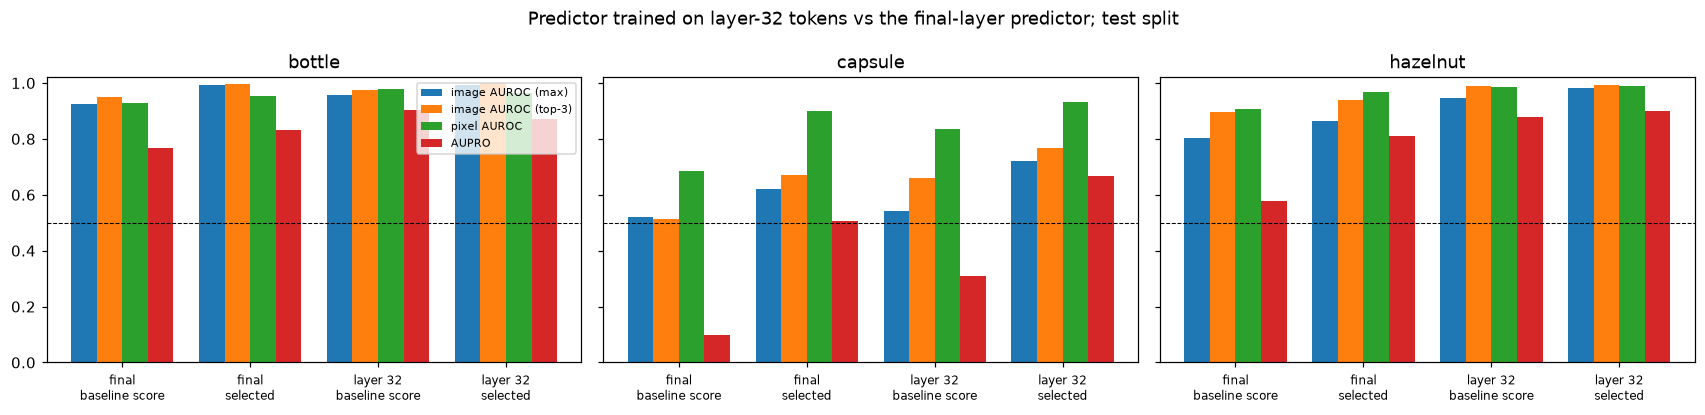

In [7]:
fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(5.2 * len(CATEGORIES), 3.8), sharey=True)
width = 0.2
for ax, category in zip(np.atleast_1d(axes), CATEGORIES):
    view = metrics_df[metrics_df.category == category].set_index('row')
    names = [LABEL[r] for r in ROWS]
    for offset, (col, label) in enumerate((('image_auroc_max', 'image AUROC (max)'), (f'image_auroc_top{K}', f'image AUROC (top-{K})'), ('pixel_auroc', 'pixel AUROC'), ('aupro', 'AUPRO'))):
        ax.bar(np.arange(len(names)) + (offset - 1.5) * width, [view.loc[n, col] for n in names], width, label=label)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels([n.replace(' / ', '\n') for n in names], fontsize=8)
    ax.set_title(category)
    ax.axhline(0.5, color='black', linewidth=0.7, linestyle='--')
    ax.set_ylim(0, 1.02)
np.atleast_1d(axes)[0].legend(fontsize=7)
fig.suptitle('Predictor trained on layer-32 tokens vs the final-layer predictor; test split')
fig.tight_layout()
plt.show()

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
(OUTPUT_ROOT / 'figures').mkdir(exist_ok=True)
if not OVERWRITE:
    existing = [OUTPUT_ROOT / n for n in OUTPUT_FILES if (OUTPUT_ROOT / n).exists()] + list((OUTPUT_ROOT / 'figures').glob('*.png'))
    if existing:
        raise FileExistsError('Refusing to overwrite: ' + ', '.join(map(str, existing)))
metrics_df.to_csv(OUTPUT_ROOT / 'layer_predictor_metrics.csv', index=False)
boot_df.to_csv(OUTPUT_ROOT / 'bootstrap_deltas.csv', index=False)
train_df.to_csv(OUTPUT_ROOT / 'training_summary.csv', index=False)
fig.savefig(OUTPUT_ROOT / 'figures' / 'layer_predictor_comparison.png', dpi=150, bbox_inches='tight')
(OUTPUT_ROOT / 'layer_predictor_summary.json').write_text(json.dumps({
    'layer': LAYER, 'same_recipe_as_baseline': True, 'settings_carried_over_from_notebook_06': SELECTED,
    'settings_reselected_for_layer_32': False, 'test_used_for_selection': False,
    'cache_identity': {k: v for k, v in IDENTITY.items()}, 'final_rows_reproduce_notebook_07': bool(consistent),
    'bootstrap': {'n': N_BOOTSTRAP, 'seed': BOOTSTRAP_SEED},
    'headline_verdicts': boot_df[boot_df.comparison.str.startswith('HEADLINE')].set_index('category').verdict.to_dict(),
}, indent=2, sort_keys=True, default=str), encoding='utf-8')
print('saved to', OUTPUT_ROOT)

## What you can and cannot say

**You can say**

* Whether a memory-free predictor trained on layer-32 tokens with the baseline recipe separates defects better than the final-layer predictor, under identical scoring, with paired-bootstrap intervals, and how close it gets to the nearest-neighbour reference.
* That the layer was chosen on synthetic validation data, confirmed on test only for the kNN reference (notebook 10), and that the scoring settings were carried over from the final-layer selection and not tuned for layer 32.

**You cannot say**

* That 32 is the best layer for a predictor: the scan measured kNN signal; a predictor could prefer another layer.
* That the carried-over scoring settings are the best ones for layer 32 (they were chosen on the final-layer predictor).
* That an interval containing 0 shows a gain or a loss.
* Anything about other seeds: one training run per category (item 13 of the plan).